In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np



ruta = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
df = pd.read_csv(f"{ruta}/dataset.csv")
print(df.shape) # (114000, 21)
df[["track_name","track_genre","acousticness","danceability","energy"]].head()

Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.
(114000, 21)


,track_name,track_genre,acousticness,danceability,energy
0,Comedy,acoustic,0.0322,0.676,0.4610
1,Ghost - Acoustic,acoustic,0.9240,0.420,0.1660
2,To Begin Again,acoustic,0.2100,0.438,0.3590
3,Can't Help Falling In Love,acoustic,0.9050,0.266,0.0596
4,Hold On,acoustic,0.4690,0.618,0.4430


In [ ]:
df["track_genre"]

,track_genre
0,acoustic
1,acoustic
2,acoustic
3,acoustic
4,acoustic
...,...
113995,world-music
113996,world-music
113997,world-music
113998,world-music


In [ ]:
# Celda 2 - nos quedamos con 2 generos para que sea legible
# Todas continuas 0-1, ninguna binaria
df2 = df[df["track_genre"].isin(["classical","dance"])].copy()
feats = ["danceability","energy","acousticness","instrumentalness","valence","tempo"]
X = df2[feats]
y = df2["track_genre"] # classical / dance

train 0.976 test 0.965


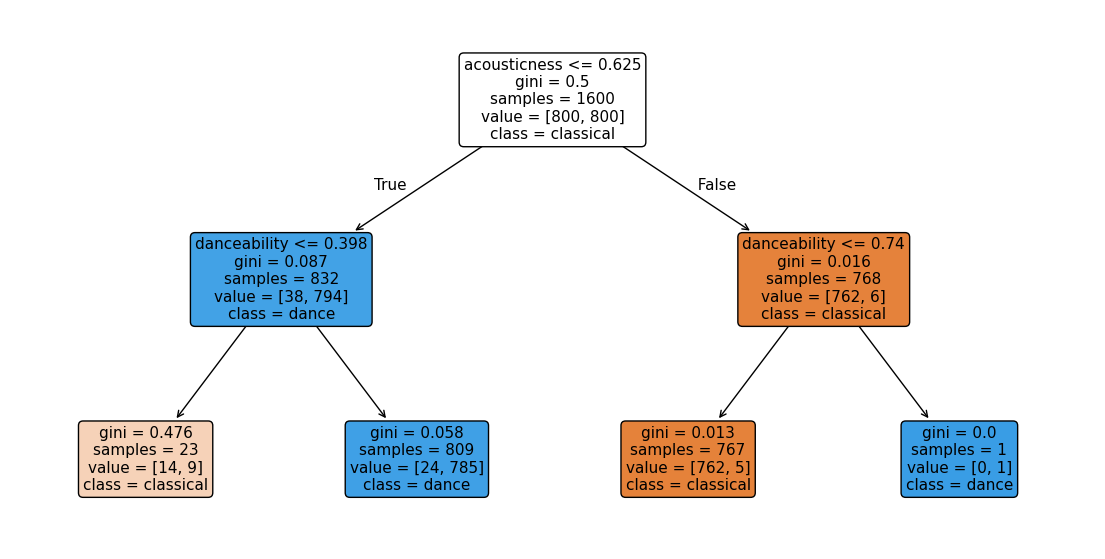

In [ ]:
# Celda 3 - arbol de 2 preguntas
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

arbol = DecisionTreeClassifier(max_depth=2, random_state=42)
arbol.fit(X_train, y_train)
print(f"train {arbol.score(X_train,y_train):.3f} test {arbol.score(X_test,y_test):.3f}")


plt.figure(figsize=(14,7))
plot_tree(arbol, feature_names=feats, class_names=["classical","dance"],
          filled=True, rounded=True, fontsize=11)

plt.show()

In [ ]:
ruta = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
df = pd.read_csv(f"{ruta}/dataset.csv")

# y NO binaria: 3 generos
df3 = df[df["track_genre"].isin(["classical","dance","techno"])].copy()
feats = ["danceability","energy","acousticness","instrumentalness","valence","tempo"]
X = df3[feats]
y = df3["track_genre"] # 3 clases
y.value_counts() # 1000 c/u, balanceado

Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.


,count
track_genre,
classical,1000
dance,1000
techno,1000


train 0.905 test 0.905


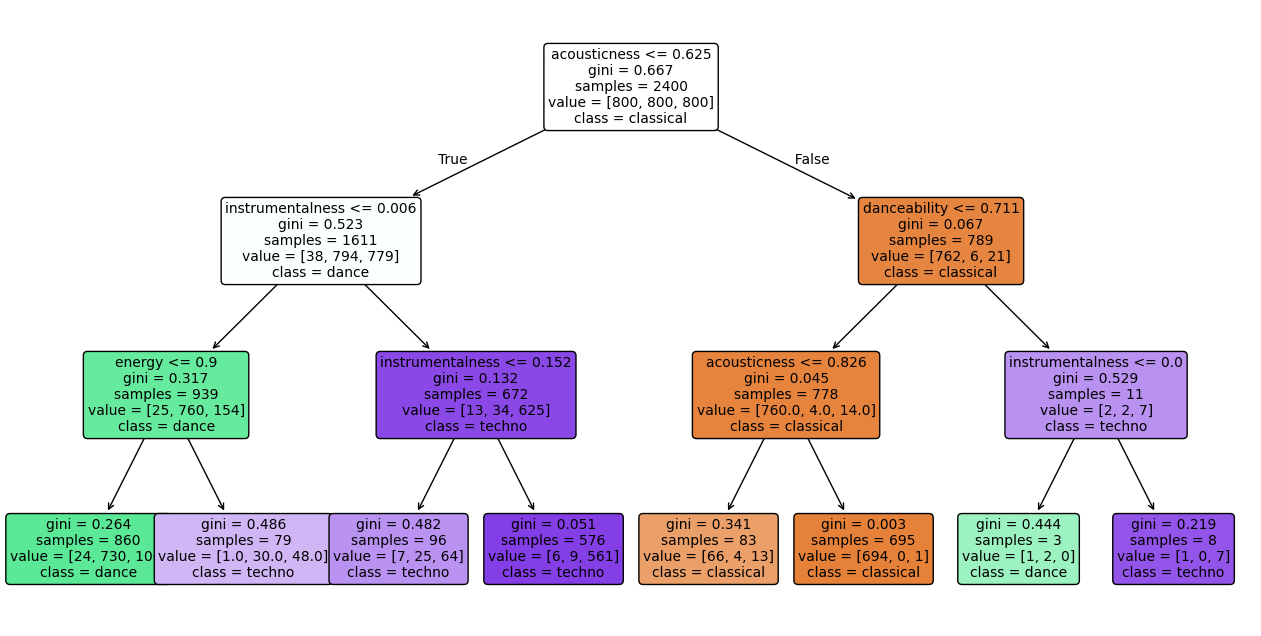

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)
print(f"train {arbol.score(X_train,y_train):.3f} test {arbol.score(X_test,y_test):.3f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(16,8))
plot_tree(arbol, feature_names=feats,
          class_names=["classical","dance","techno"],
          filled=True, rounded=True, fontsize=10)
plt.show()

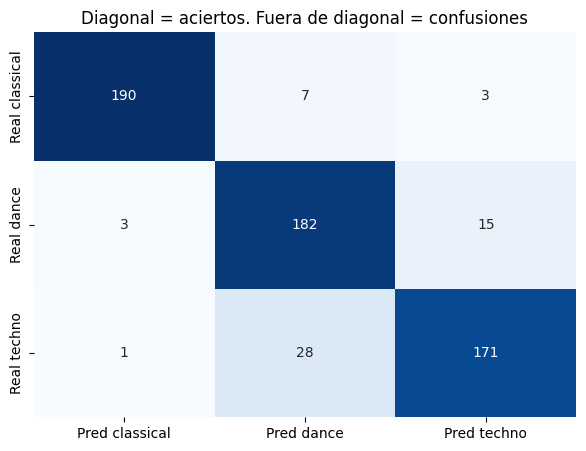

In [ ]:
cm = confusion_matrix(y_test, arbol.predict(X_test),
                      labels=["classical","dance","techno"])
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
  xticklabels=["Pred classical","Pred dance","Pred techno"],
  yticklabels=["Real classical","Real dance","Real techno"])
plt.title("Diagonal = aciertos. Fuera de diagonal = confusiones")
plt.show()

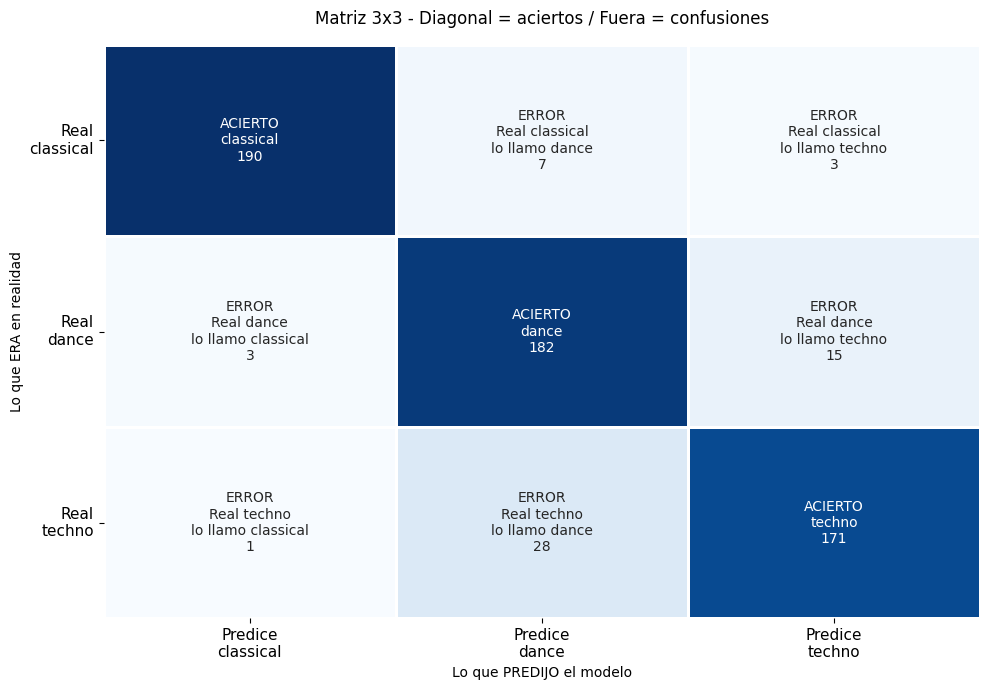

In [ ]:
labels = ["classical", "dance", "techno"]
cm = confusion_matrix(y_test, arbol.predict(X_test), labels=labels)


# 1. Arma el texto de cada cuadrante
anot = []
for i, real in enumerate(labels):
    fila = []
    for j, pred in enumerate(labels):
        v = cm[i, j]
        if i == j:
            fila.append(f"ACIERTO\n{real}\n{v}")
        else:
            fila.append(f"ERROR\nReal {real}\nlo llamo {pred}\n{v}")
    anot.append(fila)
anot = np.array(anot)

# 2. Dibuja
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=anot, fmt="", cmap="Blues",
            cbar=False, linewidths=1, linecolor="white",
            annot_kws={"size":10})

plt.xticks([0.5,1.5,2.5],
  ["Predice\nclassical","Predice\ndance","Predice\ntechno"], fontsize=11)
plt.yticks([0.5,1.5,2.5],
  ["Real\nclassical","Real\ndance","Real\ntechno"], rotation=0, fontsize=11)

plt.title("Matriz 3x3 - Diagonal = aciertos / Fuera = confusiones", pad=15)
plt.xlabel("Lo que PREDIJO el modelo")
plt.ylabel("Lo que ERA en realidad")
plt.tight_layout()
plt.show()